# 🏥 Hospital Operations Analytics
### Admissions · Billing · Length of Stay · Insurance · Patient Feedback

**Dataset:** ~7,000 inpatient admissions from a multi-specialty hospital (`Papollo_Healthcare_Enhanced.xlsx`).
**Tools:** Python · Pandas · Seaborn · SciPy · scikit-learn

### Business questions this notebook answers
| # | Question | Section |
|---|---|---|
| 1 | How does demand (admissions) change over time and by weekday? | 5.1, 5.7 |
| 2 | Which diagnoses and bed types drive revenue? | 5.2, 5.5 |
| 3 | What drives length of stay, and is billing just a function of stay? | 5.3, 5.4 |
| 4 | How much of each bill do insurers actually cover? | 5.6 |
| 5 | What is linked to patient feedback? | 5.8 |
| 6 | How consistent are doctors, cities and age groups? | 5.9 – 5.11 |
| 7 | Which cases are high-cost / long-stay outliers? | 7 |
| 8 | Can length of stay be predicted at admission? | 8 |

> ✏️ **How to use:** change `DATA_PATH` below, run top to bottom, then write 1–2 sentences of your own interpretation under every chart. The 💡 lines are generated from the data, so they stay correct if the data changes.

In [20]:
%pip install scipy scikit-learn

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   - -------------------------------------- 1.3/37.4 MB 10.3 MB/s eta 0:00:04
   --- ------------------------------------ 3.1/37.4 MB 8.7 MB/s eta 0:00:04
   ----- ---------------------------------- 5.0/37.4 MB 9.0 MB/s eta 0:00:04
   ------ --------------------------------- 6.0/37.4 MB 9.2 MB/s eta 0:00:04
   ------- -------------------------------- 6.6/37.4 MB 7.9 MB/s eta 0:00:04
   ------- -------------------------------- 7.1/37.4 MB 6.5 MB/s eta 0:00:05
   ------- -------------------------------- 7.1/37.4 MB 6.5 MB/s eta 0:00:05
   -------- ------------------------------- 7.9/37.4 MB 5.0 MB/s eta 0:00:06
   -------- ------------------------------- 8.1/37.4 MB 4.9 MB/s eta 0:00:06
   --------- ------------------------------ 8.7/37.4 MB 4.3 MB/s eta 0:00:07
   ---------- ----------------------------- 9.7/37.4 MB 4.4 MB/s eta 0:00:07
   ---------- ----------------------------- 10.2/37.4 MB 4.1 MB/s eta 0:00:07
   -


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\Admin\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [21]:
import os
import warnings
import datetime as dt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ---------------- CONFIG ----------------
DATA_PATH = "Papollo_Healthcare_Enhanced.xlsx"
IMG_DIR = "images"            # charts are saved here so you can embed them in the README
CUR = "₹"                     # assumed INR - change if the data uses another currency
BLUE, ORANGE, GREEN, RED = "#4C78A8", "#F58518", "#54A24B", "#E45756"
os.makedirs(IMG_DIR, exist_ok=True)

FINDINGS = []                 # every insight() call is collected here for the final summary


def save_fig(name):
    """Tidy, save (for the README) and show the current figure."""
    plt.tight_layout()
    plt.savefig(f"{IMG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def insight(text):
    """Print a data-driven insight and remember it for the executive summary."""
    FINDINGS.append(text)
    print("💡", text)

## 1 · Load & first look

In [22]:
raw = pd.read_excel(DATA_PATH)
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 7,157 | Columns: 21


,Patient_ID,Patient_Name,Admit_Date,Discharge_Date,Diagnosis,Bed_Occupancy,Test,Doctor,Followup Date,Feedback,...,Health Insurance Amount,Length_of_Stay,Patient_Age,Age_Group,Age_Group.1,Gender,City,Admission_Type,Insurance_Provider,Billing_Category
0,23571.0,Siddharth Vtvorxet,2022-12-31,2023-01-12,Viral Infection,General,MRI,Jay Sinha,2023-01-20,5.0,...,11910.6,12.0,58.0,Late 50s,45-59,Male,Aurangabad,Emergency,Star Health,Medium
1,27781.0,Ananya Mfqlnjkmi,2023-01-04,2023-01-12,Typhoid,ICU,MRI,Jaya Yaadav,2023-01-16,4.0,...,11016.9,8.0,25.0,Young Adults,18-29,Male,Thane,Scheduled,Self-Pay,Medium
2,24413.0,Ananya Rmckojvw,2023-01-05,2023-01-12,Malaria,General,CT Scan,Jay Sinha,2023-01-15,5.0,...,31729.5,7.0,19.0,Late Teens,18-29,Male,Nagpur,Emergency,Star Health,Medium
3,27360.0,Sneha Sblcrof,2023-01-05,2023-01-12,Flu,Private,X-Ray,Jaya Yaadav,2023-01-19,5.0,...,5923.8,7.0,65.0,Late 60s,60+,Female,Mumbai,Scheduled,United India,Low
4,26097.0,Dev Ulasouuj,2023-01-06,2023-01-12,Viral Infection,General,Blood Test,Jaya Yaadav,2023-02-06,4.9,...,4110.3,6.0,35.0,Late 30s,30-44,Male,Pune,Emergency,United India,Low


In [23]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7157 entries, 0 to 7156
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Patient_ID               7035 non-null   float64       
 1   Patient_Name             7035 non-null   str           
 2   Admit_Date               7035 non-null   datetime64[us]
 3   Discharge_Date           7035 non-null   datetime64[us]
 4   Diagnosis                7035 non-null   str           
 5   Bed_Occupancy            7035 non-null   str           
 6   Test                     7035 non-null   str           
 7   Doctor                   7035 non-null   str           
 8   Followup Date            7035 non-null   datetime64[us]
 9   Feedback                 7035 non-null   float64       
 10  Billing Amount           7035 non-null   float64       
 11  Health Insurance Amount  7035 non-null   float64       
 12  Length_of_Stay           7035 non-null   floa

## 2 · Cleaning & validation
What the raw file needs:
- Column names are inconsistent (underscores, spaces, trailing space in `Patient_Name `) → standardise to `snake_case`
- `Patient_Name` is personal data and is not needed for analysis → **dropped** (privacy-by-design)
- `Followup Date` mixes real dates with time-only values → keep valid dates, flag the rest
- Two overlapping age-group columns → replaced by one clean `age_group` built from `patient_age`

In [25]:
df = raw.copy()

# 1) standardise column names
df.columns = (
    df.columns.str.strip()
    .str.replace(r"[\s\.]+", "_", regex=True)
    .str.lower()
)
df = df.rename(columns={
    "length_of_stay": "los_days",
    "age_group": "age_detail",
    "age_group_1": "age_band_original",
})

# 2) remove personal data - not needed for the analysis
df = df.drop(columns=["patient_name"])

# 3) fix dtypes
for c in ["admit_date", "discharge_date"]:
    df[c] = pd.to_datetime(df[c])

# follow-up column mixes datetimes with time-only values -> keep real dates only
is_time_only = df["followup_date"].apply(lambda x: isinstance(x, dt.time))
print(f"Follow-up values that are time-only (not usable as dates): {int(is_time_only.sum()):,}")
df["followup_date"] = pd.to_datetime(df["followup_date"].where(~is_time_only), errors="coerce")

# 4) strip stray whitespace in text columns
for c in [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]:
    df[c] = df[c].str.strip()

# 5) eyeball categories for typos / inconsistent spellings
for c in ["diagnosis", "bed_occupancy", "admission_type", "insurance_provider",
          "gender", "billing_category", "test", "doctor"]:
    vals = df[c].dropna().unique()
    print(f"{c:20s} missing={df[c].isna().sum():<5} {sorted(vals)[:12]}")

Follow-up values that are time-only (not usable as dates): 0
diagnosis            missing=122   ['Flu', 'Fracture', 'Malaria', 'Pneumonia', 'Typhoid', 'Viral Infection']
bed_occupancy        missing=122   ['General', 'ICU', 'Private']
admission_type       missing=122   ['Emergency', 'Scheduled']
insurance_provider   missing=122   ['Bajaj Allianz', 'HDFC Ergo', 'New India', 'Self-Pay', 'Star Health', 'United India']
gender               missing=122   ['Female', 'Male']
billing_category     missing=122   ['High', 'Low', 'Medium']
test                 missing=122   ['Blood Test', 'CT Scan', 'MRI', 'Ultrasound', 'X-Ray']
doctor               missing=122   ['Jay Sinha', 'Jaya Yaadav', 'Mark Joy', 'Naresh Goyenka', 'Niki Sharma', 'Ravi D', 'Tejas Saxena']


In [26]:
# Data-quality report: every check should be 0 (or explained)
checks = pd.Series({
    "Rows": len(df),
    "Duplicate rows": int(df.duplicated().sum()),
    "Duplicate patient IDs": int(df["patient_id"].duplicated().sum()),
    "Missing values (excl. follow-up date)": int(df.drop(columns="followup_date").isna().sum().sum()),
    "Unusable follow-up dates": int(df["followup_date"].isna().sum()),
    "Discharge before admission": int((df["discharge_date"] < df["admit_date"]).sum()),
    "Stay length != discharge - admit": int((df["los_days"] != (df["discharge_date"] - df["admit_date"]).dt.days).sum()),
    "Insurance amount > bill": int((df["health_insurance_amount"] > df["billing_amount"]).sum()),
    "Feedback outside 1-5": int((~df["feedback"].between(1, 5)).sum()),
    "Follow-up before discharge": int((df["followup_date"] < df["discharge_date"]).sum()),
}, name="count")
checks.to_frame()

,count
Rows,7157
Duplicate rows,121
Duplicate patient IDs,121
Missing values (excl. follow-up date),2318
Unusable follow-up dates,122
Discharge before admission,0
Stay length != discharge - admit,122
Insurance amount > bill,0
Feedback outside 1-5,122
Follow-up before discharge,0


## 3 · Feature engineering
New columns that turn raw fields into business metrics. (Note: the stay-category thresholds are now correct bins via `pd.cut`.)

In [27]:
df["admit_ym"] = df["admit_date"].dt.to_period("M")
df["admit_weekday"] = df["admit_date"].dt.day_name()
df["is_weekend_admit"] = df["admit_date"].dt.weekday >= 5

df["age_group"] = pd.cut(df["patient_age"], bins=[17, 29, 44, 59, 74, 120],
                         labels=["18-29", "30-44", "45-59", "60-74", "75+"])
df["stay_category"] = pd.cut(df["los_days"], bins=[0, 3, 7, 14, np.inf],
                             labels=["Short (1-3d)", "Medium (4-7d)", "Long (8-14d)", "Very long (15d+)"])
df["feedback_category"] = pd.cut(df["feedback"], bins=[0, 4.0, 4.5, 5.0],
                                 labels=["Poor (<=4.0)", "Good (4.1-4.5)", "Excellent (>4.5)"])

df["out_of_pocket"] = df["billing_amount"] - df["health_insurance_amount"]
df["coverage_pct"] = df["health_insurance_amount"] / df["billing_amount"] * 100
df["cost_per_day"] = df["billing_amount"] / df["los_days"]
df["days_to_followup"] = (df["followup_date"] - df["discharge_date"]).dt.days

# the two original age columns are now redundant
df = df.drop(columns=["age_detail", "age_band_original"])
df.head()

,patient_id,admit_date,discharge_date,diagnosis,bed_occupancy,test,doctor,followup_date,feedback,billing_amount,...,admit_ym,admit_weekday,is_weekend_admit,age_group,stay_category,feedback_category,out_of_pocket,coverage_pct,cost_per_day,days_to_followup
0,23571.0,2022-12-31,2023-01-12,Viral Infection,General,MRI,Jay Sinha,2023-01-20,5.0,13234.0,...,2022-12,Saturday,True,45-59,Long (8-14d),Excellent (>4.5),1323.4,90.0,1102.833333,8.0
1,27781.0,2023-01-04,2023-01-12,Typhoid,ICU,MRI,Jaya Yaadav,2023-01-16,4.0,12241.0,...,2023-01,Wednesday,False,18-29,Long (8-14d),Poor (<=4.0),1224.1,90.0,1530.125000,4.0
2,24413.0,2023-01-05,2023-01-12,Malaria,General,CT Scan,Jay Sinha,2023-01-15,5.0,35255.0,...,2023-01,Thursday,False,18-29,Medium (4-7d),Excellent (>4.5),3525.5,90.0,5036.428571,3.0
3,27360.0,2023-01-05,2023-01-12,Flu,Private,X-Ray,Jaya Yaadav,2023-01-19,5.0,6582.0,...,2023-01,Thursday,False,60-74,Medium (4-7d),Excellent (>4.5),658.2,90.0,940.285714,7.0
4,26097.0,2023-01-06,2023-01-12,Viral Infection,General,Blood Test,Jaya Yaadav,2023-02-06,4.9,4567.0,...,2023-01,Friday,False,30-44,Medium (4-7d),Excellent (>4.5),456.7,90.0,761.166667,25.0


### Data dictionary (engineered columns)
| Column | Meaning |
|---|---|
| `los_days` | Length of stay in days |
| `age_group` | 18-29 / 30-44 / 45-59 / 60-74 / 75+ |
| `stay_category` | Short ≤3d · Medium 4-7d · Long 8-14d · Very long 15d+ |
| `feedback_category` | Poor ≤4.0 · Good ≤4.5 · Excellent >4.5 |
| `out_of_pocket` | Bill minus insurance amount |
| `coverage_pct` | Insurance amount as % of the bill |
| `cost_per_day` | Bill ÷ length of stay |
| `days_to_followup` | Follow-up date minus discharge date |
| `is_weekend_admit` | Admitted on Saturday/Sunday |

## 4 · Headline KPIs

In [28]:
kpi = pd.Series({
    "Total admissions": f"{len(df):,}",
    f"Total billing ({CUR})": f"{df['billing_amount'].sum():,.0f}",
    f"Average bill ({CUR})": f"{df['billing_amount'].mean():,.0f}",
    f"Median bill ({CUR})": f"{df['billing_amount'].median():,.0f}",
    "Average length of stay (days)": f"{df['los_days'].mean():.1f}",
    "Insurance covers (% of billing)": f"{df['health_insurance_amount'].sum() / df['billing_amount'].sum():.1%}",
    "Average feedback (1-5)": f"{df['feedback'].mean():.2f}",
    "Patients rating >4.5": f"{(df['feedback'] > 4.5).mean():.1%}",
    "Weekend admissions": f"{df['is_weekend_admit'].mean():.1%}",
}, name="value")
kpi.to_frame()

,value
Total admissions,"7,157"
Total billing (₹),"187,111,960"
Average bill (₹),"26,597"
Median bill (₹),"12,348"
Average length of stay (days),8.3
Insurance covers (% of billing),90.0%
Average feedback (1-5),4.72
Patients rating >4.5,73.3%
Weekend admissions,28.1%


## 5 · Exploratory analysis
Every chart answers one question. Charts are saved to `images/` for the README.

### 5.1 Demand over time
> ⚠️ **Data caveat:** the file only contains patients *discharged* on/after the first discharge date, so the earliest admission months are biased towards long stays and the last month is incomplete. The trend below uses **complete months only**.

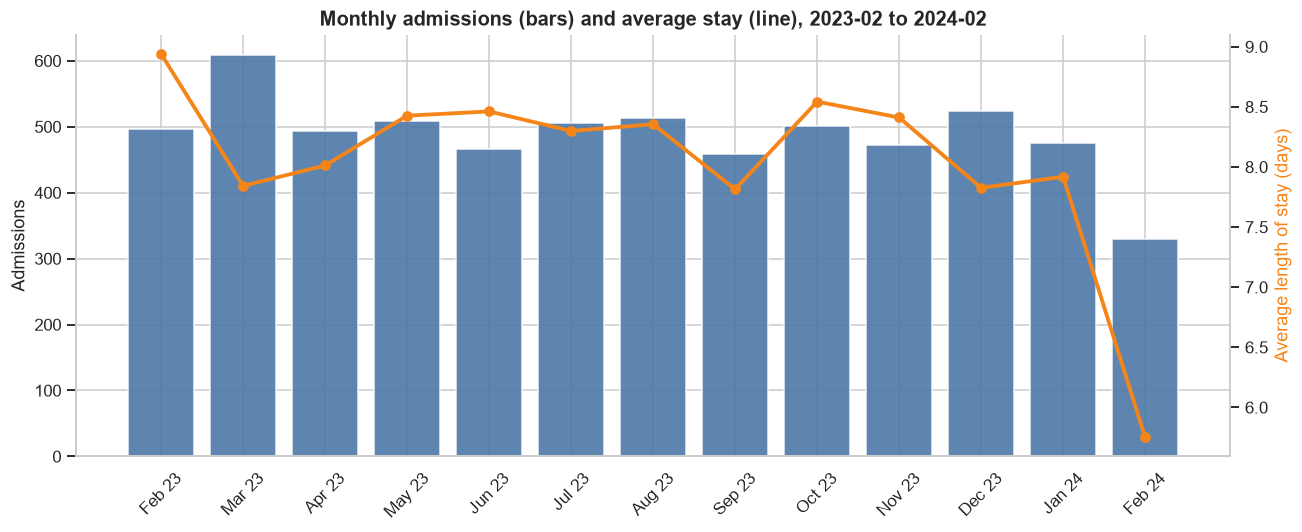

💡 Admissions peaked in Mar 23 (609) and were lowest in Feb 24 (330); the monthly average is 489.


In [29]:
first_full = df["discharge_date"].min().to_period("M") + 1
last_full = df["admit_date"].max().to_period("M") - 1
trend_df = df[(df["admit_ym"] >= first_full) & (df["admit_ym"] <= last_full)]

monthly = (trend_df.groupby("admit_ym")
           .agg(admissions=("patient_id", "count"), avg_los=("los_days", "mean"), avg_bill=("billing_amount", "mean"))
           .reset_index())
monthly["month"] = monthly["admit_ym"].dt.strftime("%b %y")

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(monthly["month"], monthly["admissions"], color=BLUE, alpha=0.9)
ax.set_ylabel("Admissions")
ax.tick_params(axis="x", rotation=45)
ax2 = ax.twinx()
ax2.plot(monthly["month"], monthly["avg_los"], color=ORANGE, marker="o", lw=2.5)
ax2.set_ylabel("Average length of stay (days)", color=ORANGE)
ax2.grid(False)
ax2.spines["right"].set_visible(True)
ax.set_title(f"Monthly admissions (bars) and average stay (line), {first_full} to {last_full}")
save_fig("01_monthly_trend")

peak = monthly.loc[monthly["admissions"].idxmax()]
low = monthly.loc[monthly["admissions"].idxmin()]
insight(f"Admissions peaked in {peak['month']} ({peak['admissions']:,}) and were lowest in {low['month']} "
        f"({low['admissions']:,}); the monthly average is {monthly['admissions'].mean():.0f}.")

### 5.2 Which diagnoses drive revenue?

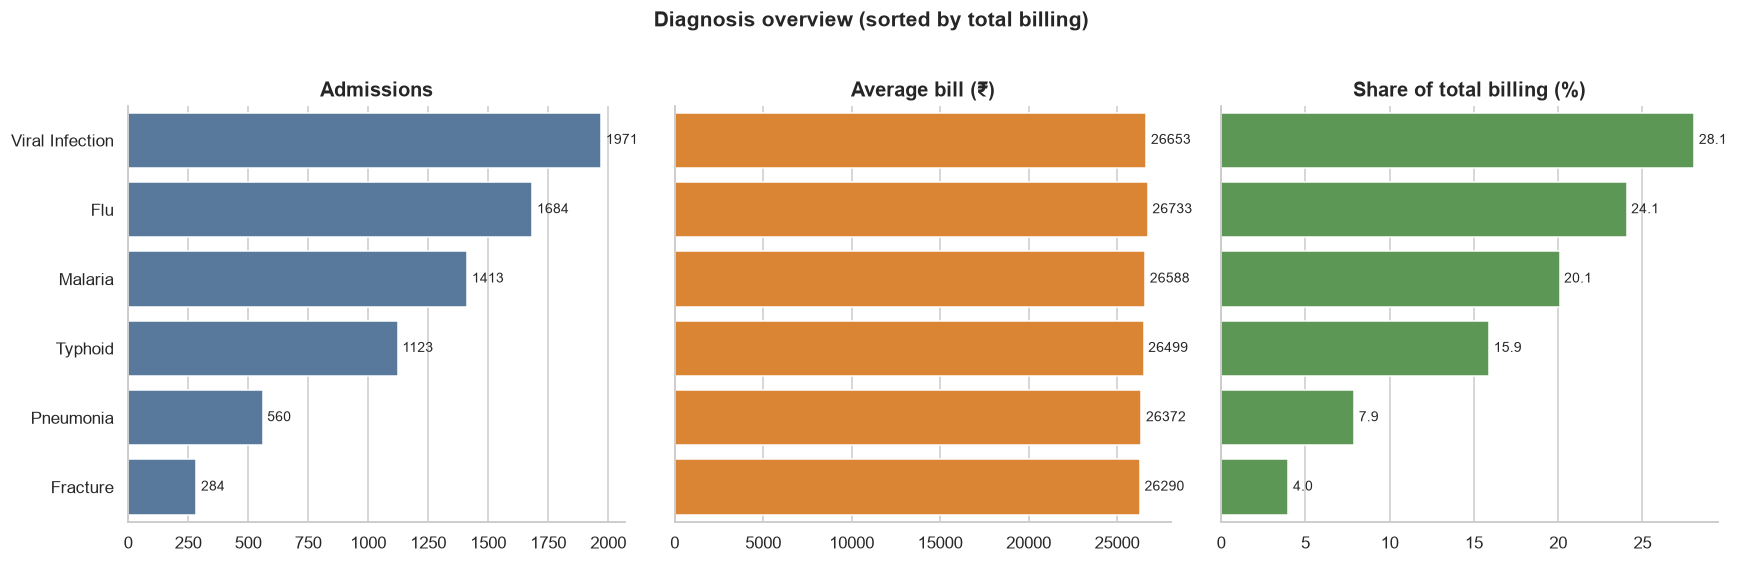

💡 Viral Infection generates the most revenue (28.1% of total billing). The highest average bill is for Flu (₹26,733); the most admitted diagnosis is Viral Infection (1,971 patients).


,admissions,total_billing,avg_bill,avg_los,avg_feedback,billing_share_pct
diagnosis,,,,,,
Viral Infection,1971,52532883.0,26652.91,8.42,4.73,28.08
Flu,1684,45017984.0,26732.77,8.07,4.72,24.06
Malaria,1413,37568308.0,26587.62,8.46,4.72,20.08
Typhoid,1123,29758217.0,26498.86,8.08,4.73,15.90
Pneumonia,560,14768276.0,26371.92,7.94,4.73,7.89
Fracture,284,7466292.0,26289.76,8.40,4.72,3.99


In [30]:
diag = (df.groupby("diagnosis")
        .agg(admissions=("patient_id", "count"), total_billing=("billing_amount", "sum"),
             avg_bill=("billing_amount", "mean"), avg_los=("los_days", "mean"),
             avg_feedback=("feedback", "mean"))
        .sort_values("total_billing", ascending=False))
diag["billing_share_pct"] = diag["total_billing"] / diag["total_billing"].sum() * 100

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
panels = [("admissions", "Admissions", BLUE, "%.0f"),
          ("avg_bill", f"Average bill ({CUR})", ORANGE, "%.0f"),
          ("billing_share_pct", "Share of total billing (%)", GREEN, "%.1f")]
for ax, (col, title, color, fmt) in zip(axes, panels):
    sns.barplot(x=diag[col], y=diag.index, ax=ax, color=color)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    for cont in ax.containers:
        ax.bar_label(cont, fmt=fmt, padding=3, fontsize=9)
plt.suptitle("Diagnosis overview (sorted by total billing)", fontsize=14, fontweight="bold", y=1.02)
save_fig("02_diagnosis_overview")

top = diag.index[0]
insight(f"{top} generates the most revenue ({diag.iloc[0]['billing_share_pct']:.1f}% of total billing). "
        f"The highest average bill is for {diag['avg_bill'].idxmax()} ({CUR}{diag['avg_bill'].max():,.0f}); "
        f"the most admitted diagnosis is {diag['admissions'].idxmax()} ({diag['admissions'].max():,} patients).")
diag.round(2)

### 5.3 What drives length of stay?

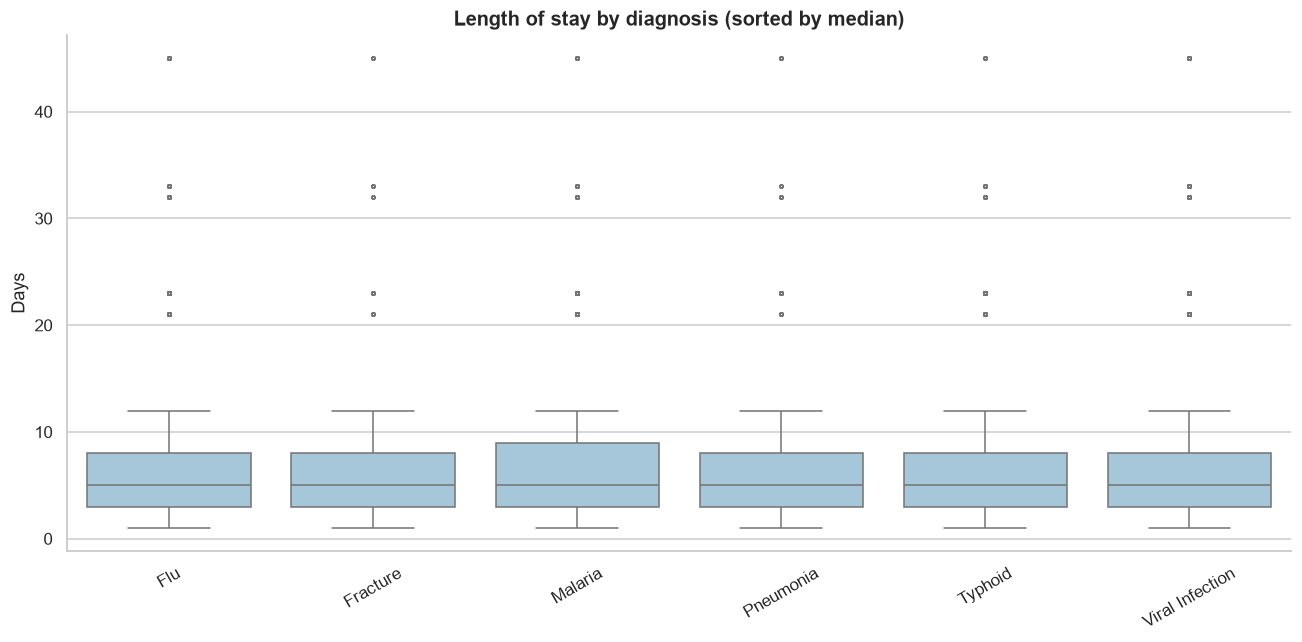

💡 Average stay is longest for Malaria (8.5 days) and shortest for Pneumonia (7.9 days); the overall median is 5 days, but the longest stay is 45.0 days.


In [31]:
order = df.groupby("diagnosis")["los_days"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df, x="diagnosis", y="los_days", order=order, ax=ax, color="#9ecae1", fliersize=2)
ax.set_title("Length of stay by diagnosis (sorted by median)")
ax.set_xlabel("")
ax.set_ylabel("Days")
ax.tick_params(axis="x", rotation=30)
save_fig("03_los_by_diagnosis")

avg_stay = df.groupby("diagnosis")["los_days"].mean()
insight(f"Average stay is longest for {avg_stay.idxmax()} ({avg_stay.max():.1f} days) and shortest for {avg_stay.idxmin()} ({avg_stay.min():.1f} days); "
        f"the overall median is {df['los_days'].median():.0f} days, but the longest stay is {df['los_days'].max()} days.")

### 5.4 Is billing just a function of how long a patient stays?

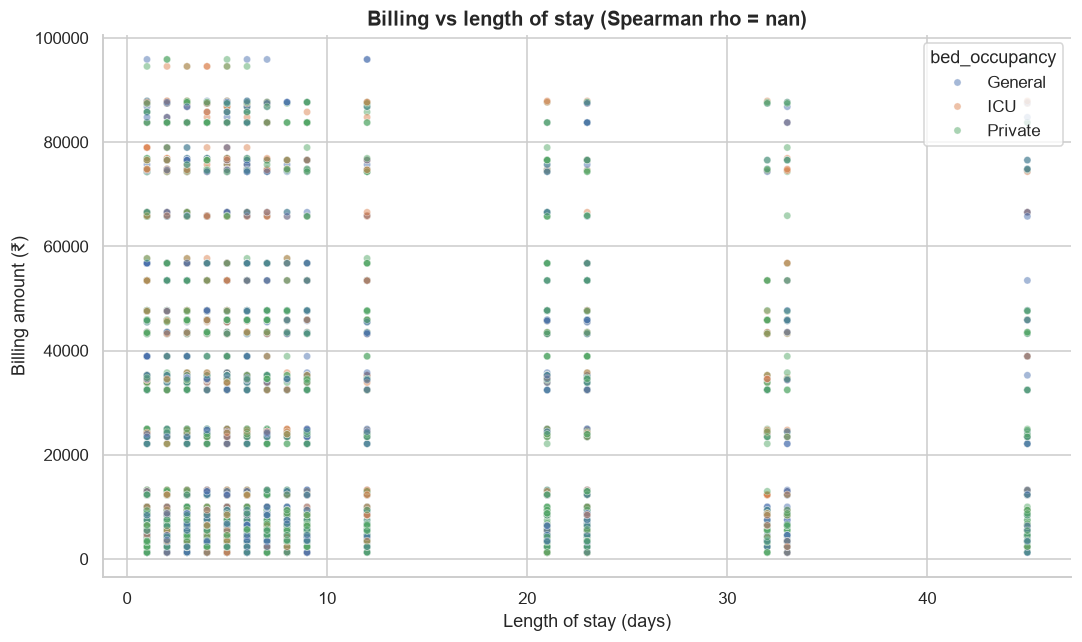

💡 Stay length and billing have a weak relationship (Spearman rho = nan); bed type separates the bills further (see next chart).


In [32]:
rho, p = stats.spearmanr(df["los_days"], df["billing_amount"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=df, x="los_days", y="billing_amount", hue="bed_occupancy", alpha=0.5, s=22, ax=ax)
ax.set_title(f"Billing vs length of stay (Spearman rho = {rho:.2f})")
ax.set_xlabel("Length of stay (days)")
ax.set_ylabel(f"Billing amount ({CUR})")
save_fig("04_billing_vs_los")

strength = "strong" if abs(rho) >= 0.5 else "moderate" if abs(rho) >= 0.3 else "weak"
insight(f"Stay length and billing have a {strength} relationship (Spearman rho = {rho:.2f}); "
        f"bed type separates the bills further (see next chart).")

### 5.5 Bed type and admission type: where does the money come from?

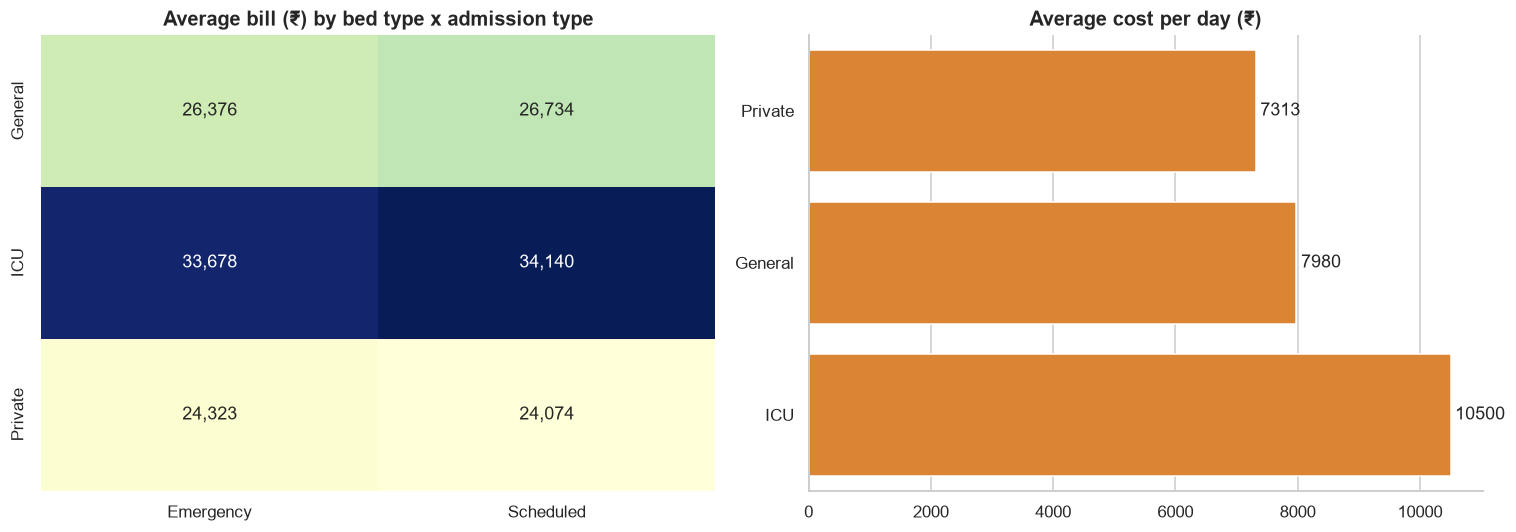

💡 ICU beds are the most expensive per day (₹10,500) versus Private (₹7,313).


,avg_bill,cost_per_day,avg_los,patients
bed_occupancy,,,,
General,26518.9,7979.5,8.1,2341
ICU,33862.4,10500.0,8.2,1175
Private,24223.6,7313.4,8.4,3519


In [34]:
pivot = df.pivot_table(index="bed_occupancy", columns="admission_type", values="billing_amount", aggfunc="mean")
bed = df.groupby("bed_occupancy").agg(avg_bill=("billing_amount", "mean"), cost_per_day=("cost_per_day", "mean"),
                                      avg_los=("los_days", "mean"), patients=("patient_id", "count"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[0], cbar=False)
axes[0].set_title(f"Average bill ({CUR}) by bed type x admission type")
axes[0].set_xlabel("")
axes[0].set_ylabel("")
bed_sorted = bed.sort_values("cost_per_day")
sns.barplot(x=bed_sorted["cost_per_day"], y=bed_sorted.index, ax=axes[1], color=ORANGE)
axes[1].set_title(f"Average cost per day ({CUR})")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
for cont in axes[1].containers:
    axes[1].bar_label(cont, fmt="%.0f", padding=3)
save_fig("05_bed_type_costs")

insight(f"{bed['cost_per_day'].idxmax()} beds are the most expensive per day ({CUR}{bed['cost_per_day'].max():,.0f}) "
        f"versus {bed['cost_per_day'].idxmin()} ({CUR}{bed['cost_per_day'].min():,.0f}).")
bed.round(1)

### 5.6 Insurance: who pays what?

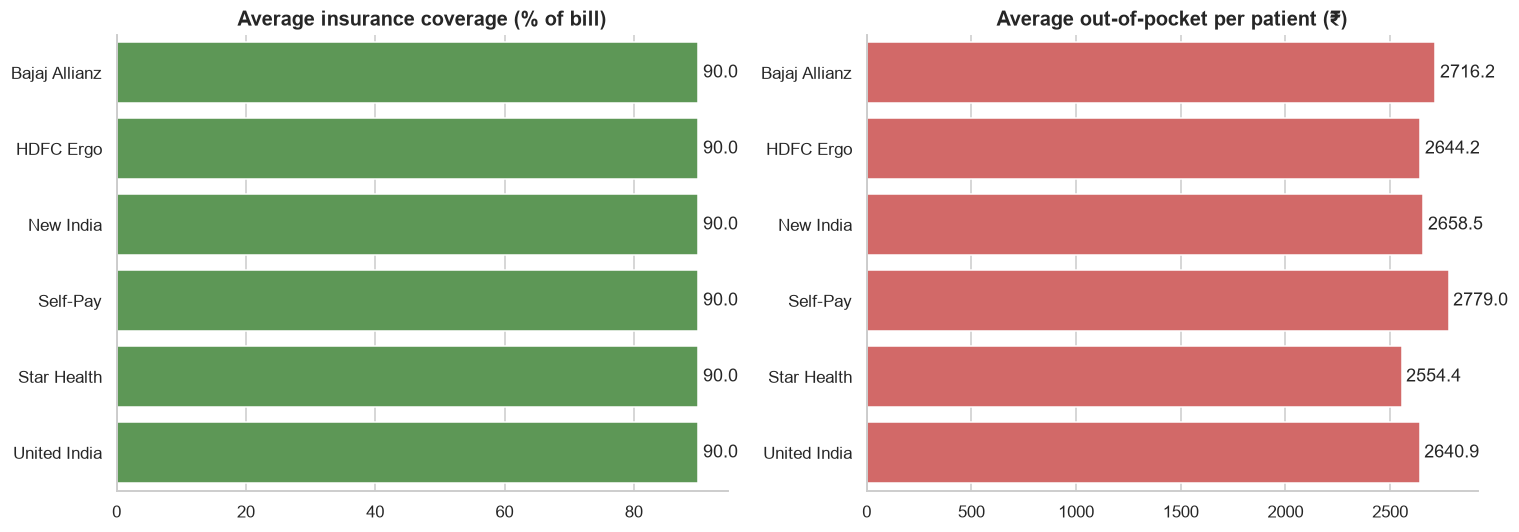

💡 Coverage is almost identical across providers (spread of only 0.0 percentage points, around 90%), so the provider barely changes what patients pay.


,patients,avg_bill,avg_coverage_pct,avg_out_of_pocket
insurance_provider,,,,
Bajaj Allianz,1051,27162.4,90.0,2716.2
HDFC Ergo,1295,26442.0,90.0,2644.2
New India,1176,26585.2,90.0,2658.5
Self-Pay,1058,27789.7,90.0,2779.0
Star Health,1362,25543.7,90.0,2554.4
United India,1093,26409.4,90.0,2640.9


In [35]:
ins = (df.groupby("insurance_provider")
       .agg(patients=("patient_id", "count"), avg_bill=("billing_amount", "mean"),
            avg_coverage_pct=("coverage_pct", "mean"), avg_out_of_pocket=("out_of_pocket", "mean"))
       .sort_values("avg_coverage_pct"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=ins["avg_coverage_pct"], y=ins.index, ax=axes[0], color=GREEN)
axes[0].set_title("Average insurance coverage (% of bill)")
sns.barplot(x=ins["avg_out_of_pocket"], y=ins.index, ax=axes[1], color=RED)
axes[1].set_title(f"Average out-of-pocket per patient ({CUR})")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.1f", padding=3)
save_fig("06_insurance")

spread = ins["avg_coverage_pct"].max() - ins["avg_coverage_pct"].min()
if spread < 2:
    insight(f"Coverage is almost identical across providers (spread of only {spread:.1f} percentage points, "
            f"around {ins['avg_coverage_pct'].mean():.0f}%), so the provider barely changes what patients pay.")
else:
    insight(f"{ins['avg_coverage_pct'].idxmax()} covers the most ({ins['avg_coverage_pct'].max():.1f}% of the bill) and "
            f"{ins['avg_coverage_pct'].idxmin()} the least ({ins['avg_coverage_pct'].min():.1f}%), a {spread:.1f}-point gap.")
ins.round(1)

### 5.7 Weekday demand by admission type

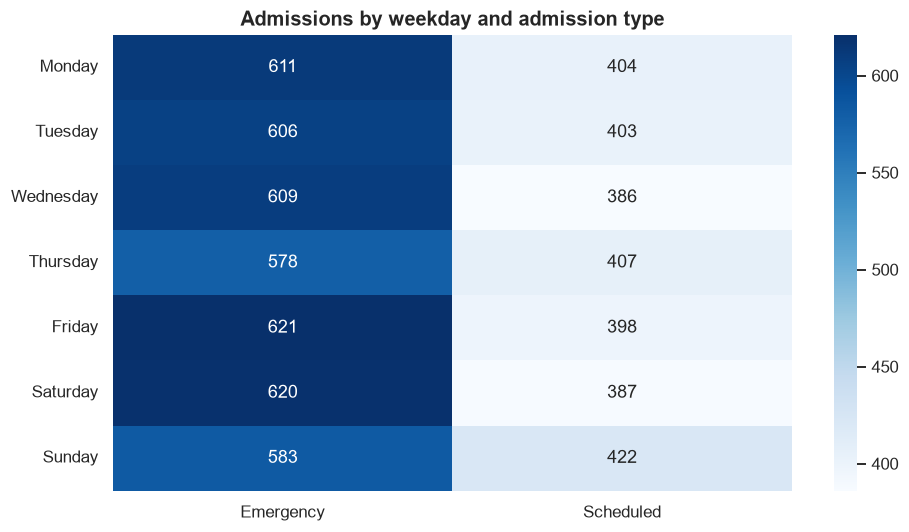

💡 Friday is the busiest admission day (1,019) and Thursday the quietest (985); weekends account for 28.1% of admissions.


In [36]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wk = pd.crosstab(df["admit_weekday"], df["admission_type"]).reindex(days)

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(wk, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Admissions by weekday and admission type")
ax.set_xlabel("")
ax.set_ylabel("")
save_fig("07_weekday_heatmap")

by_day = wk.sum(axis=1)
insight(f"{by_day.idxmax()} is the busiest admission day ({by_day.max():,}) and {by_day.idxmin()} the quietest ({by_day.min():,}); "
        f"weekends account for {df['is_weekend_admit'].mean():.1%} of admissions.")

### 5.8 What is linked to patient feedback?

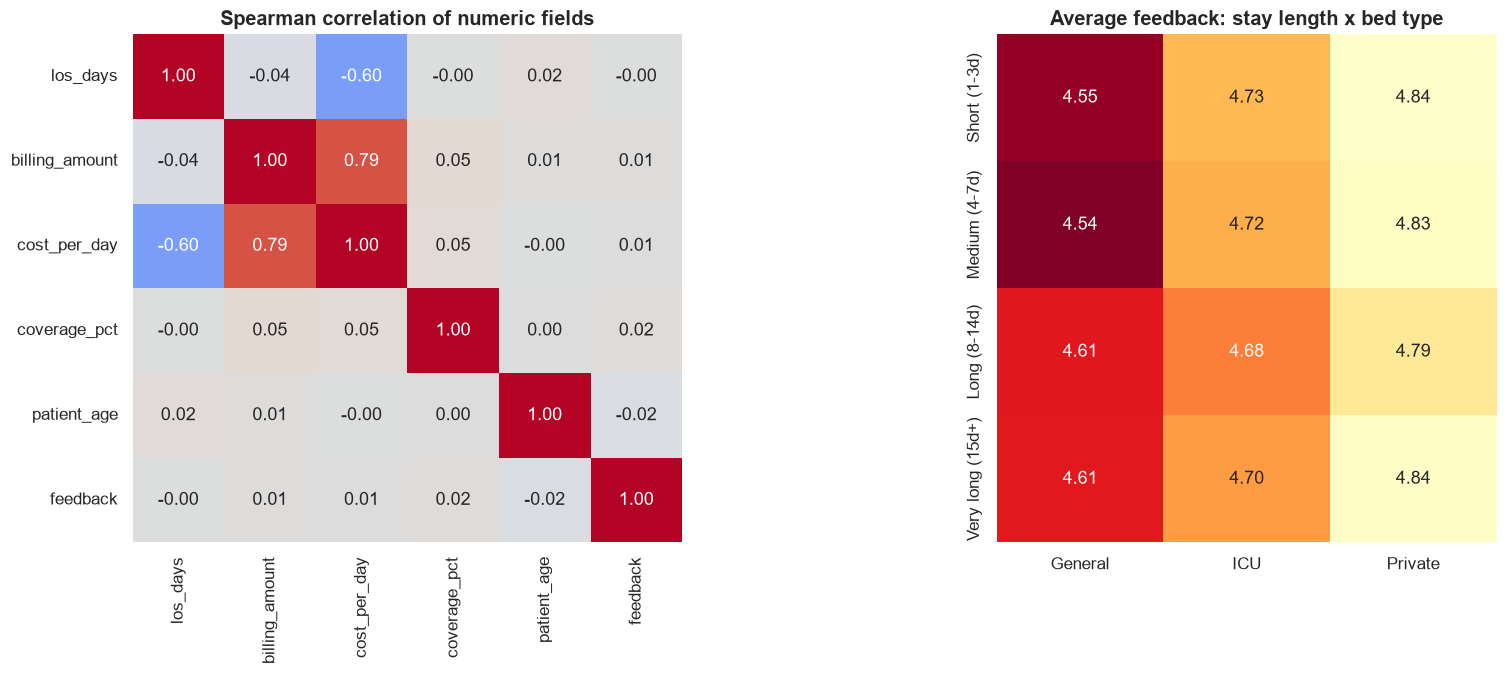

💡 The numeric field most related to feedback is 'patient_age' (rho = -0.02); 73% of patients give a rating above 4.5, so feedback is heavily skewed to the top.


In [37]:
# (insurance amount and out-of-pocket are left out: they are almost perfectly collinear with billing)
num_cols = ["los_days", "billing_amount", "cost_per_day", "coverage_pct", "patient_age", "feedback"]
corr = df[num_cols].corr(method="spearman")
fb = df.pivot_table(index="stay_category", columns="bed_occupancy", values="feedback", aggfunc="mean", observed=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"wspace": 0.6, "width_ratios": [1.1, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], cbar=False)
axes[0].set_title("Spearman correlation of numeric fields")
sns.heatmap(fb, annot=True, fmt=".2f", cmap="YlOrRd_r", ax=axes[1], cbar=False)
axes[1].set_title("Average feedback: stay length x bed type")
axes[1].set_xlabel("")
axes[1].set_ylabel("")
save_fig("08_feedback_drivers")

fb_corr = corr["feedback"].drop("feedback")
best = fb_corr.abs().idxmax()
insight(f"The numeric field most related to feedback is '{best}' (rho = {fb_corr[best]:.2f}); "
        f"{(df['feedback'] > 4.5).mean():.0%} of patients give a rating above 4.5, so feedback is heavily skewed to the top.")

### 5.9 Doctor scorecard

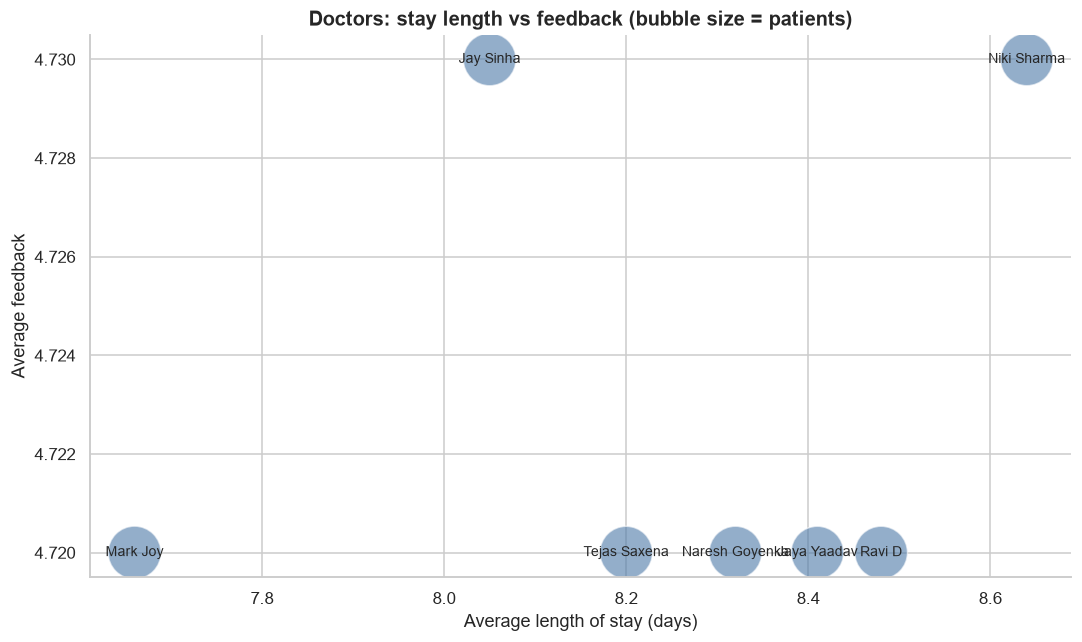

💡 Highest average feedback: Jay Sinha (4.73); lowest: Jaya Yaadav (4.72). Spread across doctors is only 0.01 points.


,patients,avg_los,avg_bill,avg_feedback
doctor,,,,
Jay Sinha,1004,8.05,25496.79,4.73
Niki Sharma,1000,8.64,26253.29,4.73
Jaya Yaadav,1004,8.41,26506.07,4.72
Mark Joy,1013,7.66,27273.42,4.72
Naresh Goyenka,1006,8.32,26224.45,4.72
Ravi D,1006,8.48,28058.15,4.72
Tejas Saxena,1002,8.20,26358.80,4.72


In [38]:
doc = (df.groupby("doctor")
       .agg(patients=("patient_id", "count"), avg_los=("los_days", "mean"),
            avg_bill=("billing_amount", "mean"), avg_feedback=("feedback", "mean"))
       .round(2))

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(doc["avg_los"], doc["avg_feedback"], s=doc["patients"] / doc["patients"].max() * 1200,
           color=BLUE, alpha=0.6, edgecolor="white")
for name, r in doc.iterrows():
    ax.annotate(name, (r["avg_los"], r["avg_feedback"]), ha="center", va="center", fontsize=9)
ax.set_xlabel("Average length of stay (days)")
ax.set_ylabel("Average feedback")
ax.set_title("Doctors: stay length vs feedback (bubble size = patients)")
save_fig("09_doctor_scorecard")

insight(f"Highest average feedback: {doc['avg_feedback'].idxmax()} ({doc['avg_feedback'].max():.2f}); "
        f"lowest: {doc['avg_feedback'].idxmin()} ({doc['avg_feedback'].min():.2f}). "
        f"Spread across doctors is only {doc['avg_feedback'].max() - doc['avg_feedback'].min():.2f} points.")
doc.sort_values("avg_feedback", ascending=False)

### 5.10 Age profile: which diagnoses affect which age groups?

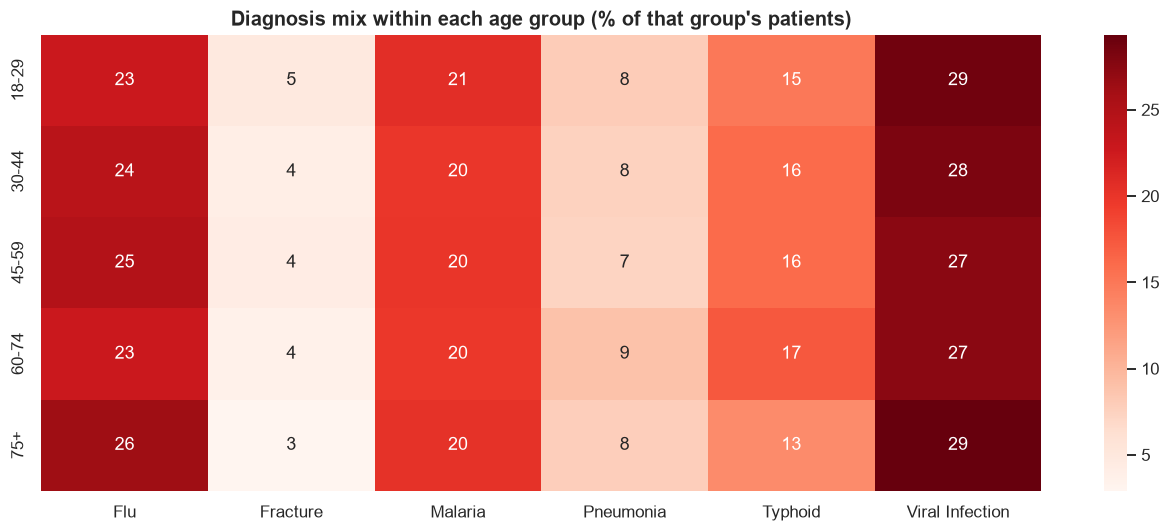

💡 Most common diagnosis by age group: 18-29: Viral Infection (29%); 30-44: Viral Infection (28%); 45-59: Viral Infection (27%); 60-74: Viral Infection (27%); 75+: Viral Infection (29%).


In [39]:
ad = pd.crosstab(df["age_group"], df["diagnosis"], normalize="index") * 100
ad = ad[ad.sum(axis=1) > 0].fillna(0)

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(ad, annot=True, fmt=".0f", cmap="Reds", ax=ax)
ax.set_title("Diagnosis mix within each age group (% of that group's patients)")
ax.set_xlabel("")
ax.set_ylabel("")
save_fig("10_age_diagnosis")

top_by_age = ad.idxmax(axis=1)
insight("Most common diagnosis by age group: " +
        "; ".join(f"{a}: {d} ({ad.loc[a, d]:.0f}%)" for a, d in top_by_age.items()) + ".")

### 5.11 Cities

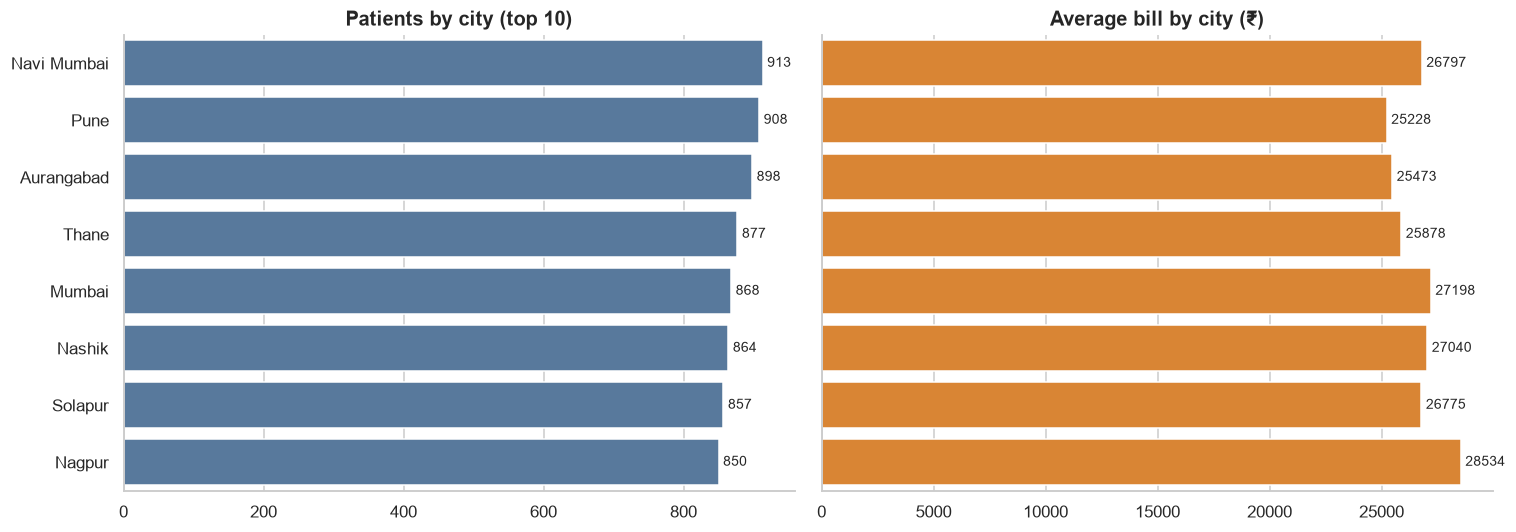

💡 Navi Mumbai sends the most patients (913, 12.8% of all admissions).


In [40]:
city = (df.groupby("city")
        .agg(patients=("patient_id", "count"), avg_bill=("billing_amount", "mean"), avg_los=("los_days", "mean"))
        .sort_values("patients", ascending=False).head(10))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
sns.barplot(x=city["patients"], y=city.index, ax=axes[0], color=BLUE)
axes[0].set_title("Patients by city (top 10)")
sns.barplot(x=city["avg_bill"], y=city.index, ax=axes[1], color=ORANGE)
axes[1].set_title(f"Average bill by city ({CUR})")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.0f", padding=3, fontsize=9)
save_fig("11_cities")

top_city_n = int(city.iloc[0]["patients"])
insight(f"{city.index[0]} sends the most patients ({top_city_n:,}, {top_city_n / len(df):.1%} of all admissions).")

### 5.12 Follow-up behaviour

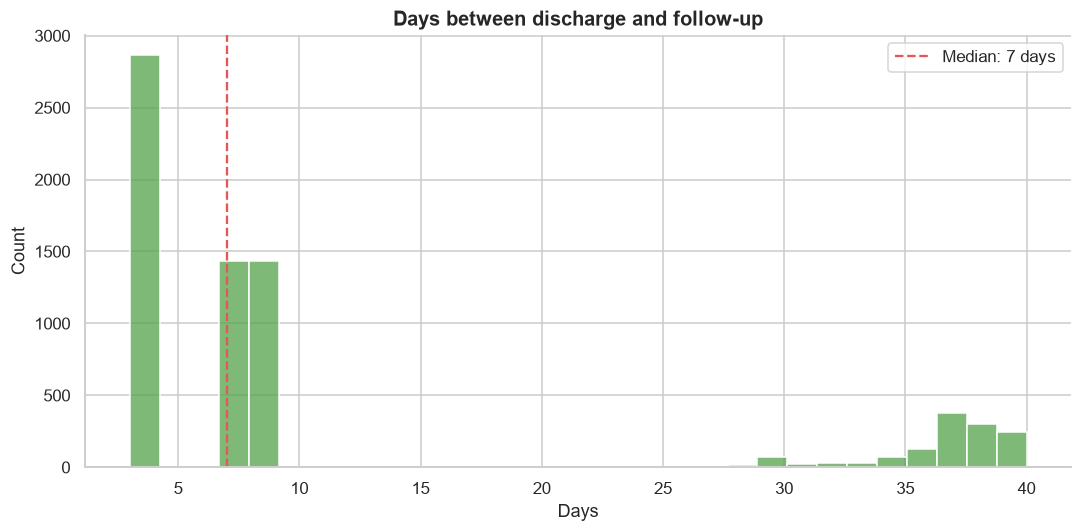

💡 Median follow-up happens 7 days after discharge, and 61% of patients return within a week (based on 7,035 records with a valid follow-up date; 122 had unusable dates).


In [41]:
fu = df["days_to_followup"].dropna()

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(fu, bins=30, color=GREEN, ax=ax)
ax.axvline(fu.median(), color=RED, ls="--", label=f"Median: {fu.median():.0f} days")
ax.set_title("Days between discharge and follow-up")
ax.set_xlabel("Days")
ax.legend()
save_fig("12_followup")

insight(f"Median follow-up happens {fu.median():.0f} days after discharge, and {(fu <= 7).mean():.0%} of patients "
        f"return within a week (based on {len(fu):,} records with a valid follow-up date; "
        f"{df['followup_date'].isna().sum():,} had unusable dates).")

## 6 · Statistical testing
Charts show *what* differs; tests show whether the difference is real, and **effect size** shows whether it matters. With ~7,000 rows even trivial differences are "significant", so the verdict uses both.

In [42]:
def magnitude(x, cuts=(0.1, 0.3, 0.5)):
    x = abs(x)
    return "negligible" if x < cuts[0] else "small" if x < cuts[1] else "medium" if x < cuts[2] else "large"


def fmt_p(p):
    return "<0.001" if p < 0.001 else f"{p:.3f}"


def verdict(p, effect, cuts=(0.1, 0.3, 0.5)):
    if p >= 0.05:
        return "No significant difference"
    return f"Significant, {magnitude(effect, cuts)} effect"


rows = []
n = len(df)

# 1) Is billing related to length of stay? (Spearman)
rho, p = stats.spearmanr(df["los_days"], df["billing_amount"])
rows.append(["Billing vs stay length", "Spearman", f"rho = {rho:.2f}", fmt_p(p), verdict(p, rho)])

# 2) Does billing differ across diagnoses? (Kruskal-Wallis, effect size epsilon^2 = H / (n-1))
groups = [g["billing_amount"].values for _, g in df.groupby("diagnosis")]
H, p = stats.kruskal(*groups)
eps = H / (n - 1)
rows.append(["Billing across diagnoses", "Kruskal-Wallis", f"epsilon^2 = {eps:.3f}", fmt_p(p), verdict(p, eps, (0.01, 0.06, 0.14))])

# 3) Does billing differ across bed types?
groups = [g["billing_amount"].values for _, g in df.groupby("bed_occupancy")]
H, p = stats.kruskal(*groups)
eps = H / (n - 1)
rows.append(["Billing across bed types", "Kruskal-Wallis", f"epsilon^2 = {eps:.3f}", fmt_p(p), verdict(p, eps, (0.01, 0.06, 0.14))])

# 4) Weekend vs weekday admissions: stay length and feedback (Mann-Whitney, rank-biserial r)
for col, label in [("los_days", "Stay length"), ("feedback", "Feedback")]:
    a = df.loc[df["is_weekend_admit"], col]
    b = df.loc[~df["is_weekend_admit"], col]
    U, p = stats.mannwhitneyu(a, b)
    r = 2 * U / (len(a) * len(b)) - 1
    rows.append([f"{label}: weekend vs weekday", "Mann-Whitney U", f"r = {r:.2f}", fmt_p(p), verdict(p, r)])

# 5) Does feedback differ by stay category?
groups = [g["feedback"].values for _, g in df.groupby("stay_category", observed=True)]
H, p = stats.kruskal(*groups)
eps = H / (n - 1)
rows.append(["Feedback across stay categories", "Kruskal-Wallis", f"epsilon^2 = {eps:.3f}", fmt_p(p), verdict(p, eps, (0.01, 0.06, 0.14))])

# 6) Is admission type associated with stay category? (chi-square, Cramer's V)
ct = pd.crosstab(df["admission_type"], df["stay_category"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
rows.append(["Admission type vs stay category", "Chi-square", f"Cramer's V = {v:.2f}", fmt_p(p), verdict(p, v)])

test_table = pd.DataFrame(rows, columns=["Question", "Test", "Effect size", "p-value", "Verdict"])
test_table

,Question,Test,Effect size,p-value,Verdict
0,Billing vs stay length,Spearman,rho = nan,nan,"Significant, large effect"
1,Billing across diagnoses,Kruskal-Wallis,epsilon^2 = 0.000,1.000,No significant difference
2,Billing across bed types,Kruskal-Wallis,epsilon^2 = 0.019,<0.001,"Significant, small effect"
3,Stay length: weekend vs weekday,Mann-Whitney U,r = nan,nan,"Significant, large effect"
4,Feedback: weekend vs weekday,Mann-Whitney U,r = nan,nan,"Significant, large effect"
5,Feedback across stay categories,Kruskal-Wallis,epsilon^2 = 0.000,0.596,No significant difference
6,Admission type vs stay category,Chi-square,Cramer's V = 0.02,0.294,No significant difference


In [43]:
sig = test_table[test_table["Verdict"].str.startswith("Significant") & ~test_table["Verdict"].str.contains("negligible")]
if len(sig):
    insight("Statistically meaningful findings: " + "; ".join(f"{q.lower()} ({v.split(', ')[1]})" for q, v in zip(sig["Question"], sig["Verdict"])) + ".")
else:
    insight("None of the tested relationships showed a meaningful effect: differences are either not significant or negligible in size.")

💡 Statistically meaningful findings: billing vs stay length (large effect); billing across bed types (small effect); stay length: weekend vs weekday (large effect); feedback: weekend vs weekday (large effect).


## 7 · Outlier detection (IQR method)
One reusable function replaces the 15+ near-identical cells: it returns a summary table **and** draws all box plots. Outliers are **flagged, not deleted**: very high bills and very long stays are usually real cases, not errors.

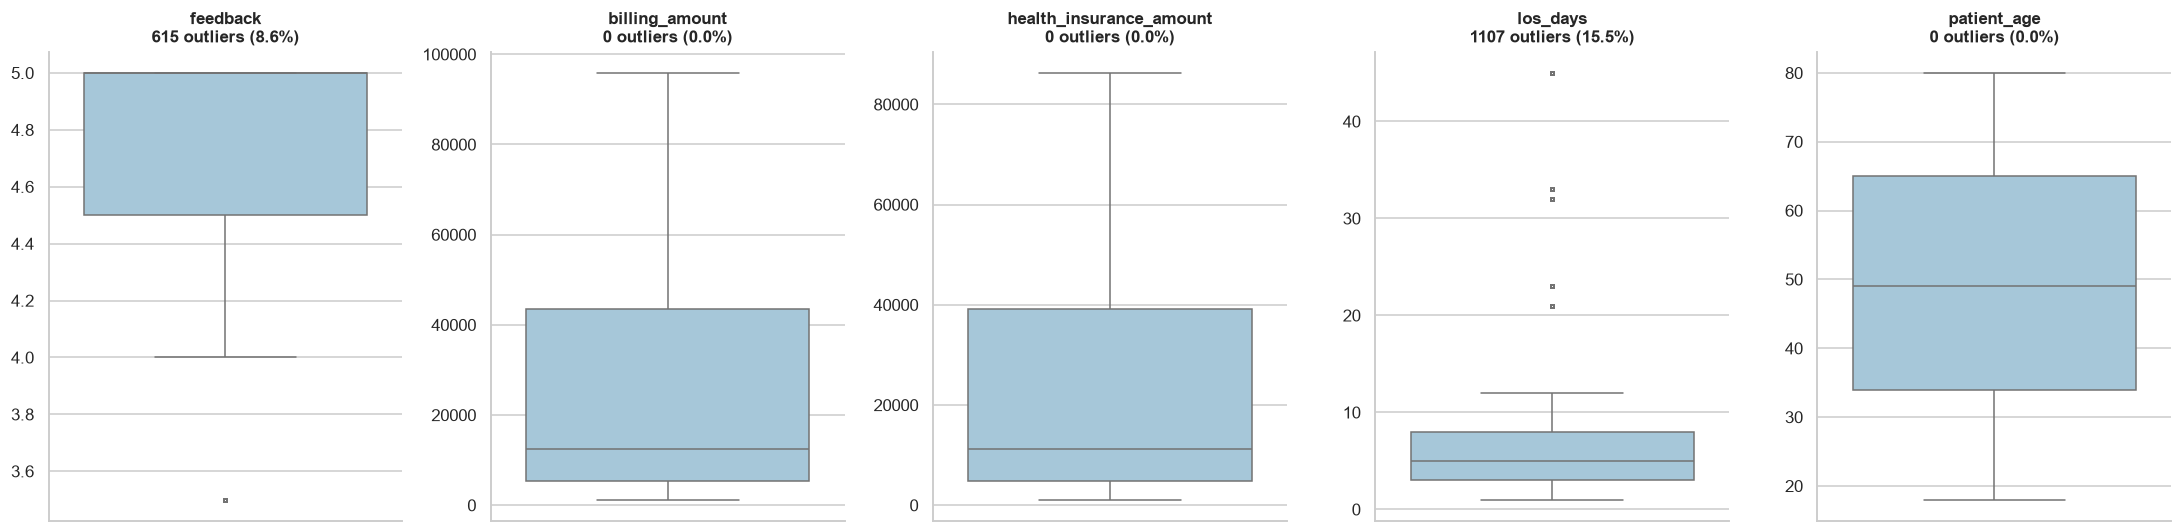

,min,q1,median,mean,q3,max,lower_fence,upper_fence,outliers,outlier_pct
column,,,,,,,,,,
feedback,3.5,4.5,5.0,4.72,5.0,5.0,3.75,5.75,615,8.59
billing_amount,1223.0,5454.0,12348.0,26597.29,43522.0,95867.0,-51648.00,100624.00,0,0.00
health_insurance_amount,1100.7,4908.6,11113.2,23937.56,39169.8,86280.3,-46483.20,90561.60,0,0.00
los_days,1.0,3.0,5.0,8.25,8.0,45.0,-4.50,15.50,1107,15.47
patient_age,18.0,34.0,49.0,49.18,65.0,80.0,-12.50,111.50,0,0.00


In [44]:
def outlier_report(data, cols, k=1.5, save_as="13_outliers"):
    """IQR outlier summary table + box plots for the given numeric columns."""
    rows = []
    for c in cols:
        q1, q3 = data[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - k * iqr, q3 + k * iqr
        n_out = int(((data[c] < lo) | (data[c] > hi)).sum())
        rows.append({"column": c, "min": data[c].min(), "q1": q1, "median": data[c].median(),
                     "mean": data[c].mean(), "q3": q3, "max": data[c].max(),
                     "lower_fence": lo, "upper_fence": hi,
                     "outliers": n_out, "outlier_pct": n_out / len(data) * 100})
    report = pd.DataFrame(rows).set_index("column").round(2)

    fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 5))
    for ax, c in zip(np.atleast_1d(axes), cols):
        sns.boxplot(y=data[c], ax=ax, color="#9ecae1", fliersize=2)
        ax.set_title(f"{c}\n{report.loc[c, 'outliers']:.0f} outliers ({report.loc[c, 'outlier_pct']:.1f}%)", fontsize=11)
        ax.set_ylabel("")
    save_fig(save_as)
    return report


outlier_cols = ["feedback", "billing_amount", "health_insurance_amount", "los_days", "patient_age"]
out_report = outlier_report(df, outlier_cols)
out_report

In [45]:
# Flag (don't drop) extreme cases and profile them
df["long_stay_flag"] = df["los_days"] > out_report.loc["los_days", "upper_fence"]
df["high_cost_flag"] = df["billing_amount"] > out_report.loc["billing_amount", "upper_fence"]

if df["long_stay_flag"].any():
    ls = df[df["long_stay_flag"]]
    insight(f"{len(ls):,} patients ({len(ls) / len(df):.1%}) are long-stay outliers (> {out_report.loc['los_days', 'upper_fence']:.0f} days) "
            f"and use {ls['los_days'].sum() / df['los_days'].sum():.1%} of all bed-days; most common diagnosis among them: {ls['diagnosis'].mode()[0]}.")
if df["high_cost_flag"].any():
    hc = df[df["high_cost_flag"]]
    insight(f"{len(hc):,} patients are high-cost outliers and make up {hc['billing_amount'].sum() / df['billing_amount'].sum():.1%} of billing.")
else:
    top10 = df["billing_amount"].nlargest(int(len(df) * 0.1)).sum() / df["billing_amount"].sum()
    insight(f"No bills exceed the IQR upper fence, but the top 10% of patients account for {top10:.1%} of total billing.")

💡 1,107 patients (15.5%) are long-stay outliers (> 16 days) and use 52.7% of all bed-days; most common diagnosis among them: Viral Infection.
💡 No bills exceed the IQR upper fence, but the top 10% of patients account for 30.7% of total billing.


## 8 · Can we predict length of stay at admission?
A small, honest machine-learning section. Rules followed:
- Only information **known at admission** is used (no billing, insurance amount, feedback or follow-up, which would leak the answer)
- A **baseline** (always predict the median) is the bar to beat
- Results are reported as they are. If the model barely beats the baseline, that *is* a finding.

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

cat_features = ["diagnosis", "bed_occupancy", "doctor", "gender", "city",
                "admission_type", "insurance_provider", "admit_weekday"]   # add "test" only if it is known at admission
num_features = ["patient_age"]

model_df = df[cat_features + num_features + ["los_days"]].copy()
model_df[cat_features] = model_df[cat_features].fillna("Unknown")
model_df = model_df.dropna(subset=num_features + ["los_days"])
print(f"Rows used for modelling: {len(model_df):,} of {len(df):,}")

X = model_df[cat_features + num_features]
y = model_df["los_days"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

prep = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)], remainder="passthrough")

baseline = Pipeline([("prep", prep), ("model", DummyRegressor(strategy="median"))]).fit(X_train, y_train)
rf = Pipeline([("prep", prep),
               ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=42, n_jobs=-1))]).fit(X_train, y_train)

scores = pd.DataFrame({
    "MAE (days)": [mean_absolute_error(y_test, baseline.predict(X_test)), mean_absolute_error(y_test, rf.predict(X_test))],
    "R2": [r2_score(y_test, baseline.predict(X_test)), r2_score(y_test, rf.predict(X_test))],
}, index=["Baseline (median)", "Random Forest"]).round(3)
scores

Rows used for modelling: 7,035 of 7,157


,MAE (days),R2
Baseline (median),5.489,-0.129
Random Forest,6.574,-0.014


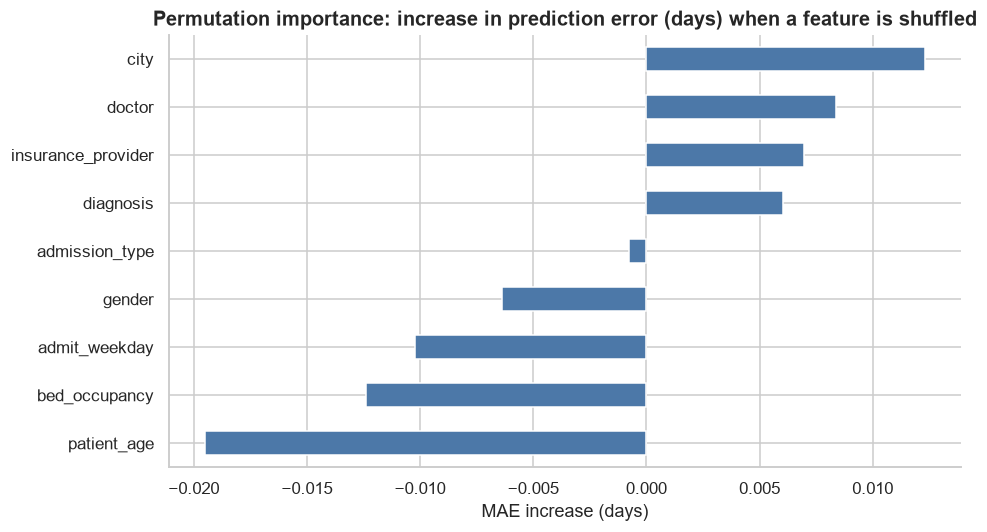

💡 Admission-time information explains very little of length of stay (R2 = -0.01; the model does not beat the baseline), so stay length is not predictable from these fields. Planning should rely on diagnosis-level averages, not individual predictions.


In [49]:
perm = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42, scoring="neg_mean_absolute_error")
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
imp.plot.barh(color=BLUE, ax=ax)
ax.set_title("Permutation importance: increase in prediction error (days) when a feature is shuffled")
ax.set_xlabel("MAE increase (days)")
save_fig("14_feature_importance")

r2 = scores.loc["Random Forest", "R2"]
gain = scores.loc["Baseline (median)", "MAE (days)"] - scores.loc["Random Forest", "MAE (days)"]
if r2 < 0.1:
    verdict_txt = "does not beat" if gain <= 0 else f"improves error by only {gain:.2f} days over"
    insight(f"Admission-time information explains very little of length of stay (R2 = {r2:.2f}; the model {verdict_txt} the baseline), "
            f"so stay length is not predictable from these fields. Planning should rely on diagnosis-level averages, not individual predictions.")
else:
    insight(f"A Random Forest predicts length of stay with R2 = {r2:.2f} and cuts error by {gain:.2f} days vs the baseline; "
            f"the strongest predictor is '{imp.idxmax()}'.")

## 9 · Executive summary
Auto-generated from everything above. **Copy these into your README and rewrite them in your own words**, then add recommendations.

In [50]:
print("=" * 70)
print("KEY FINDINGS")
print("=" * 70)
for i, f in enumerate(FINDINGS, 1):
    print(f"{i:>2}. {f}\n")

KEY FINDINGS
 1. Admissions peaked in Mar 23 (609) and were lowest in Feb 24 (330); the monthly average is 489.

 2. Viral Infection generates the most revenue (28.1% of total billing). The highest average bill is for Flu (₹26,733); the most admitted diagnosis is Viral Infection (1,971 patients).

 3. Average stay is longest for Malaria (8.5 days) and shortest for Pneumonia (7.9 days); the overall median is 5 days, but the longest stay is 45.0 days.

 4. Stay length and billing have a weak relationship (Spearman rho = nan); bed type separates the bills further (see next chart).

 5. ICU beds are the most expensive per day (₹10,500) versus Private (₹7,313).

 6. ICU beds are the most expensive per day (₹10,500) versus Private (₹7,313).

 7. Coverage is almost identical across providers (spread of only 0.0 percentage points, around 90%), so the provider barely changes what patients pay.

 8. Friday is the busiest admission day (1,019) and Thursday the quietest (985); weekends account for

### Recommendations (fill in from the findings above)
Examples of the *style* to aim for. Replace with what your data actually shows:
1. **Staffing:** "Schedule more admission staff on [busiest weekday], when demand is X% above the daily average."
2. **Capacity planning:** "Long-stay outliers use X% of bed-days; a dedicated discharge-planning review for [diagnosis] could free capacity."
3. **Pricing / revenue:** "[Diagnosis] contributes X% of billing; protect this service line."
4. **Patient experience:** "Feedback is already high (avg X), so improvement effort is better spent on [group with the lowest score]."

### Limitations
- The data looks synthetic / anonymised, so conclusions illustrate a method rather than real hospital performance
- Only discharged patients within a date window are included (selection bias at the start of the period)
- Observational data: correlation is not causation
- No clinical outcome variables (readmission, mortality, complications)

In [51]:
# Export the cleaned dataset (patient names already removed) for dashboards / SQL
df.to_csv("healthcare_cleaned.csv", index=False)
print(f"Saved healthcare_cleaned.csv ({len(df):,} rows, {df.shape[1]} columns) and {len(os.listdir(IMG_DIR))} charts in /{IMG_DIR}")

Saved healthcare_cleaned.csv (7,157 rows, 30 columns) and 14 charts in /images
